# TD-MPC2: a latent world model learned with TD, planned with MPPI

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/tdmpc2.ipynb)

[TD-MPC2](https://arxiv.org/abs/2310.16828) ([code](https://github.com/nicklashansen/tdmpc2), [site](https://www.tdmpc2.com)) learns a world model with no decoder: an encoder, latent dynamics, a reward head, an ensemble of Q-functions and a policy prior, all trained from what the agent collects. The latent only has to predict rewards, values and its own future, never pixels. To act, MPPI searches action sequences in the latent space, scoring each by predicted rewards over a short horizon plus the Q-value at its end.

The task: **PointMass** goal reaching. The point starts at a random spot of the unit square and must reach a goal 0.2 to 0.6 away; the observation is the point's position and the goal's, and the reward is minus the distance to the goal. Everything is learned online, from scratch, in a few minutes on a CPU.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [1]:
import torch

from torch_world import evaluation, plots
from torch_world.envs import PointMass
from torch_world.models import TDMPC2
from torch_world.models.tdmpc import state_encoder
from torch_world.planning import MPPI

torch.manual_seed(0)
EPISODE, ENVS, HORIZON = 25, 32, 3

## Model and planner
A small TD-MPC2: 64-dimensional SimNorm latents (8 simplices of 8), 128-unit MLPs and the paper's five Q-functions. The discount follows the reference's rule for 25-step episodes. MPPI plans 3 steps ahead with 256 sequences, 12 of them proposed by the policy prior; its later calls start from the previous plan, shifted by one step.

In [2]:
model = TDMPC2(state_encoder(4, latent_dim=64, hidden_dim=128), action_dim=2, latent_dim=64, mlp_dim=128, discount=TDMPC2.episode_discount(EPISODE))
opt = torch.optim.Adam(model.param_groups(3e-4))
planner = MPPI(horizon=HORIZON, action_dim=2, num_samples=256, num_elites=32, num_pi_trajs=12, iterations=4)
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M parameters, discount {model.discount:.2f}")

0.30M parameters, discount 0.95


## Online training
Each round collects 32 episodes in parallel, then takes 100 gradient steps on windows of `HORIZON + 1` steps from all episodes so far. The first rounds act at random; after that, MPPI acts, with exploration noise from its own final std. One step updates the world model and the policy prior together (their gradients reach disjoint parameters), clips both, as the reference does, and moves the target Q-functions.

episode return per round: -10.3 -10.7 -10.0 -10.3 -17.9 -15.4 -2.4 -1.7 -1.3 -1.0 -1.1 -1.2 -1.1 -1.0 -1.2 -1.0


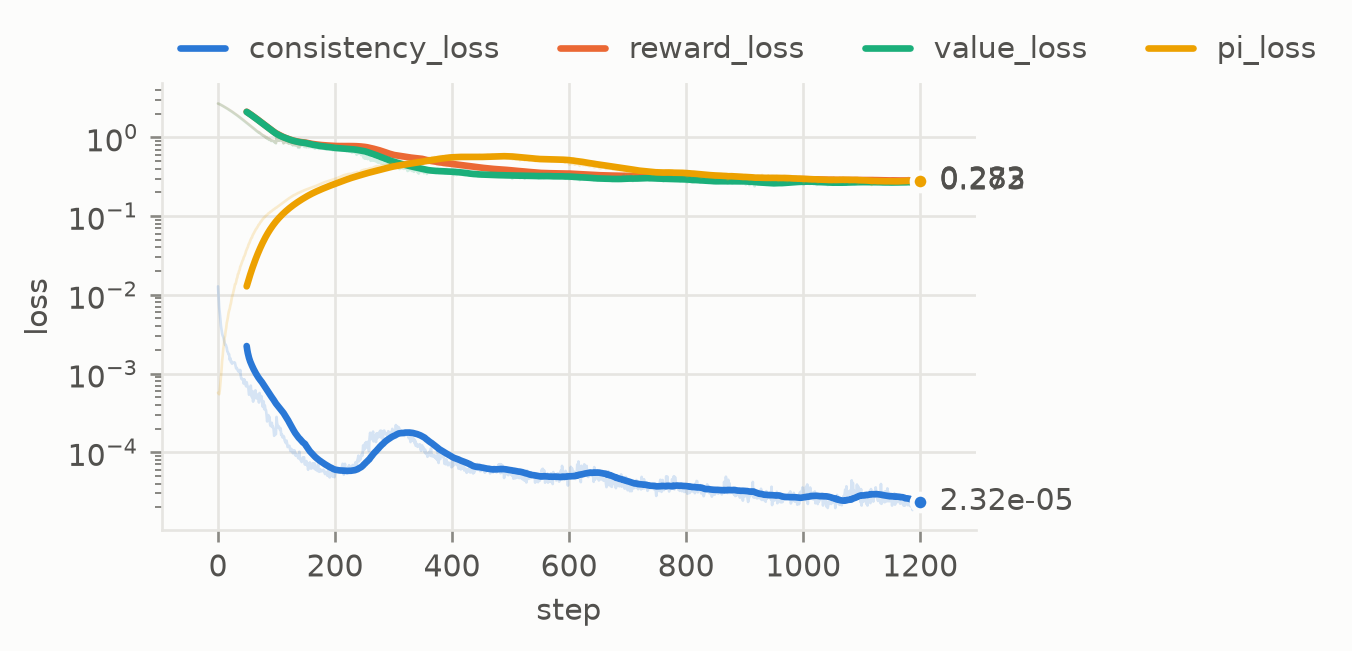

In [3]:
env = PointMass(batch_size=ENVS)
buffer = {"obs": [], "actions": [], "rewards": []}


def collect(policy):
    env.reset()
    goal = env.sample_goals((0.2, 0.6))
    planner.reset()
    obs, actions, rewards = [torch.cat([env.state, goal], -1)], [], []
    for _ in range(EPISODE):
        actions.append(policy(obs[-1]))
        env.step(actions[-1])
        rewards.append(-env.distance(env.state, goal))
        obs.append(torch.cat([env.state, goal], -1))
    for key, values in zip(buffer, (obs, actions, rewards)):
        buffer[key].append(torch.stack(values, 1))
    return buffer["rewards"][-1].sum(1).mean().item()


def sample(n):
    obs, actions, rewards = (torch.cat(buffer[k]) for k in buffer)
    episode, start = torch.randint(len(obs), (n, 1)), torch.randint(EPISODE - HORIZON + 1, (n, 1))
    t = start + torch.arange(HORIZON + 1)
    return obs[episode, t], actions[episode, t[:, :-1]], rewards[episode, t[:, :-1]]


def act(obs):
    return planner(model, model.encode(obs[:, None]), explore=True)[:, 0]


log, returns = {k: [] for k in ("consistency_loss", "reward_loss", "value_loss", "pi_loss")}, []
for _ in range(4):
    returns.append(collect(lambda obs: torch.rand(ENVS, 2) * 2 - 1))
for _ in range(12):
    model.train()
    for _ in range(100):
        out = model(*sample(256))
        opt.zero_grad()
        out["loss"].backward()
        model.clip_grad_norm(20.0)
        opt.step()
        model.update_target(0.99)
        for key in log:
            log[key].append(out[key].item())
    model.eval()
    with torch.no_grad():
        returns.append(collect(act))
print("episode return per round:", " ".join(f"{r:.1f}" for r in returns))
plots.curves(log, smooth=50)

## Goal reaching
64 new start and goal pairs, 20 steps each, success within 0.1 of the goal. Three policies: MPPI over the world model, the policy prior alone (its mean action, no search) and random actions.

In [4]:
test = PointMass(batch_size=64)
test.reset(generator=torch.Generator().manual_seed(1))
start, goal = test.state.clone(), test.sample_goals((0.2, 0.6), generator=torch.Generator().manual_seed(2))


def latent():
    return model.encode(torch.cat([test.state, goal], -1)[:, None])


planner.reset()
with torch.no_grad():
    result = evaluation.goal_reaching(
        test,
        {
            "TD-MPC2 + MPPI": lambda obs: planner(model, latent())[:, 0],
            "policy prior": lambda obs: model.pi(latent()[:, 0])[1]["mean"],
            "random actions": evaluation.random_policy(test),
        },
        start, goal, steps=20,
    )
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
TD-MPC2 + MPPI   100% [94%, 100%]     100%    3.02          0.0196     0.947   0.586       0.305        439
policy prior       95% [87%, 98%]      97%    3.34          0.0465     0.854   0.908      0.0854      0.303
random actions       6% [2%, 15%]      23%     7.8           0.407 -0.000833  0.0112        1.05     0.0056

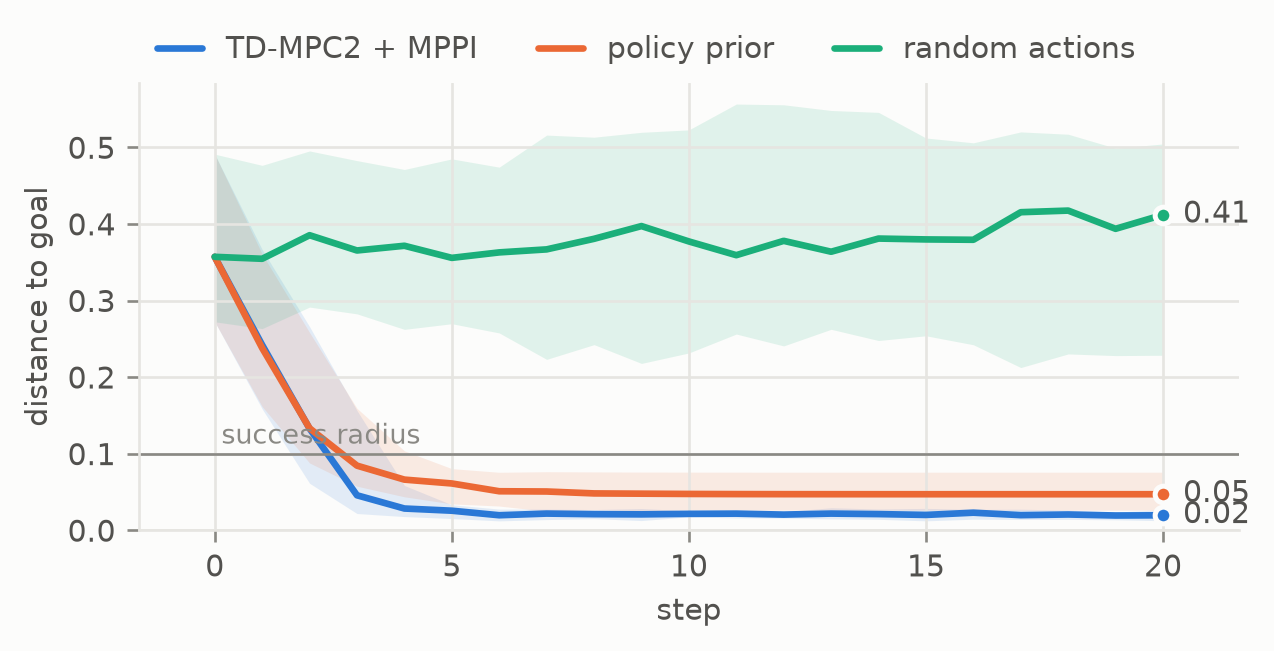

In [5]:
plots.distances(result.distances, radius=test.radius)

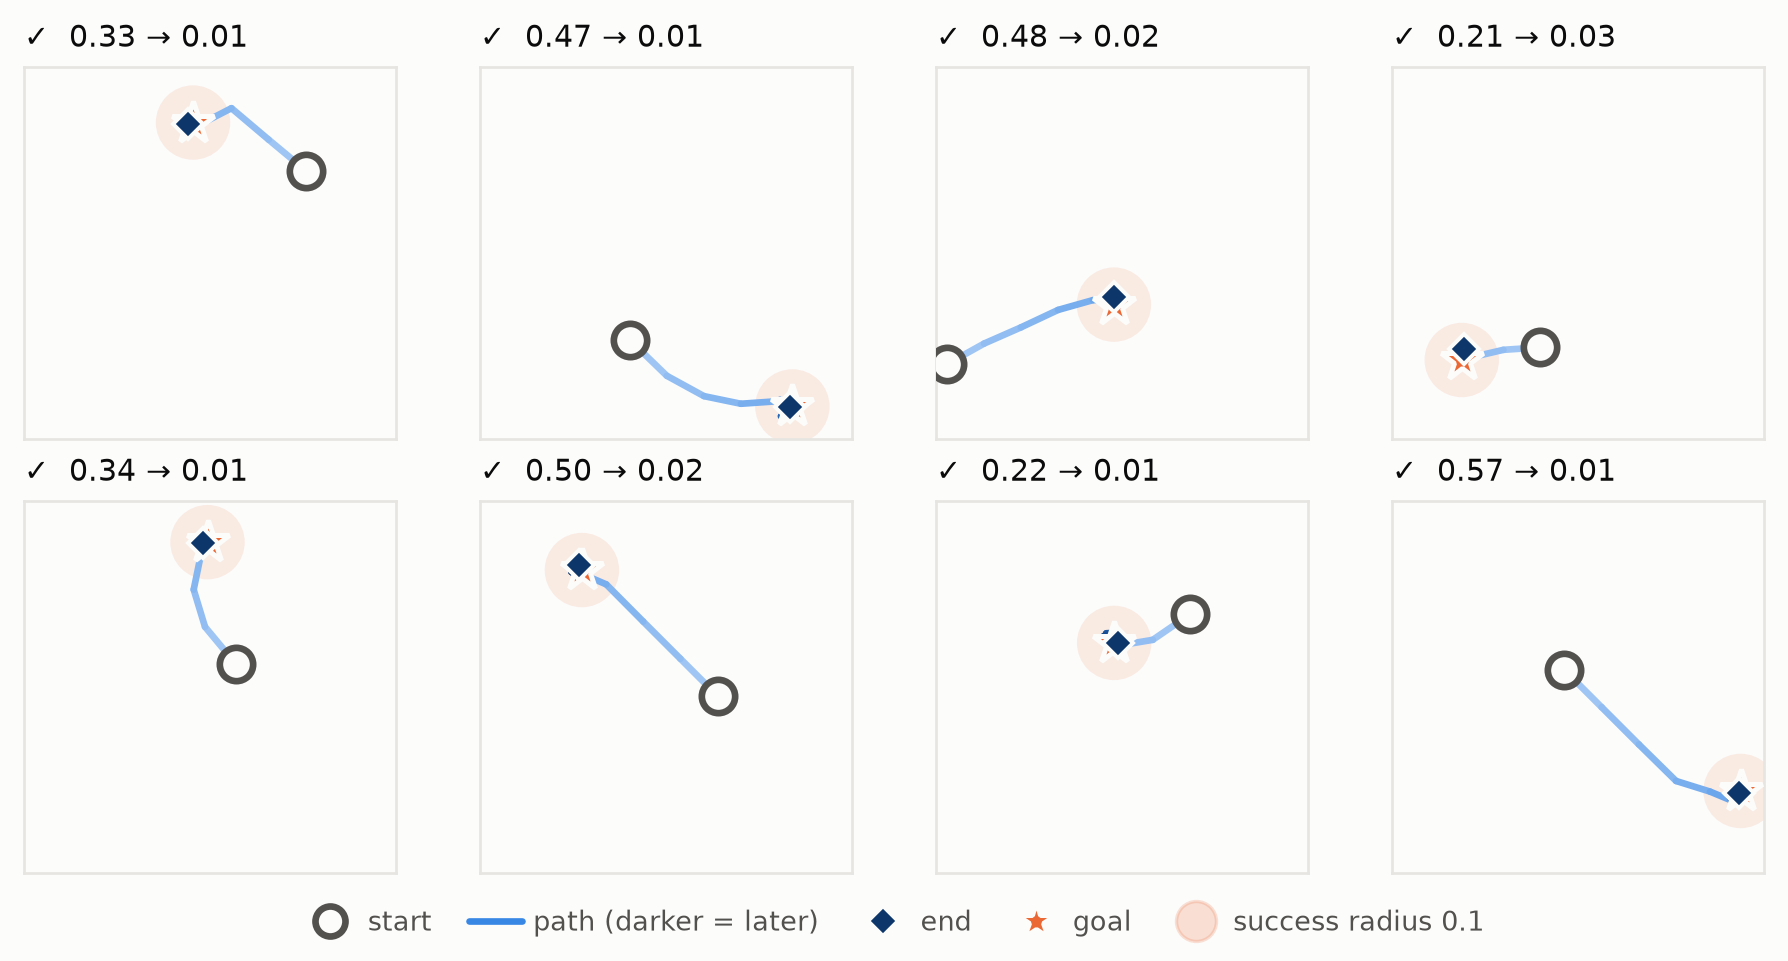

In [6]:
paths = result.paths["TD-MPC2 + MPPI"][:8]
plots.trajectories(paths, goal[:8], radius=test.radius, success=result.success["TD-MPC2 + MPPI"][:8])

## What the model imagines
From the first observation of each test episode, the dynamics unroll the actions MPPI took, open loop, and the reward head reads every imagined latent. Without seeing any later observation, the predicted rewards match the real ones while the point approaches the goal. The model trains on 3-step windows, and over these 20 open-loop steps its predictions drift slowly; MPPI only imagines 3 steps at a time and replans after every one.

mean absolute error of imagined rewards: 0.020


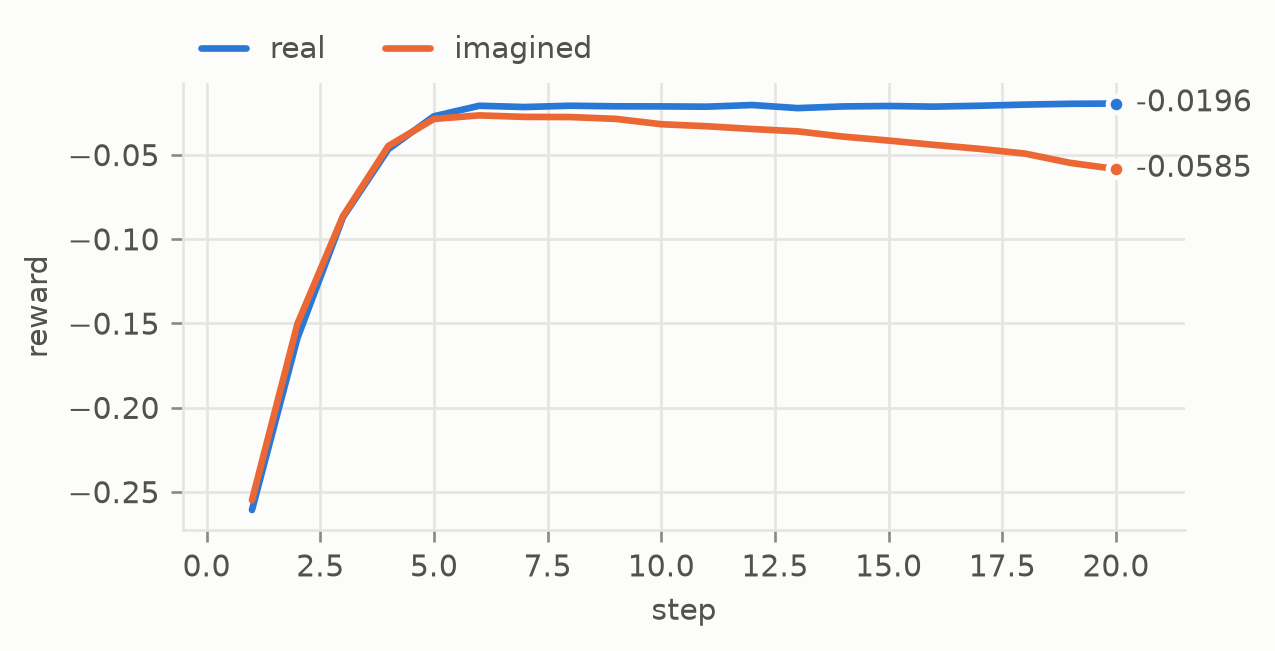

In [7]:
actions = result.actions["TD-MPC2 + MPPI"]
with torch.no_grad():
    z = model.rollout(model.encode(torch.cat([start, goal], -1)[:, None]), actions)
    imagined = model.two_hot_inv(model.reward(torch.cat([z[:, :-1], actions], -1)))
real = -result.distances["TD-MPC2 + MPPI"][:, 1:]
steps = range(1, real.size(1) + 1)
print(f"mean absolute error of imagined rewards: {(imagined - real).abs().mean():.3f}")
plots.curves({"real": (steps, real.mean(0).tolist()), "imagined": (steps, imagined.mean(0).tolist())}, smooth=1, logy=False, ylabel="reward")

## Summary

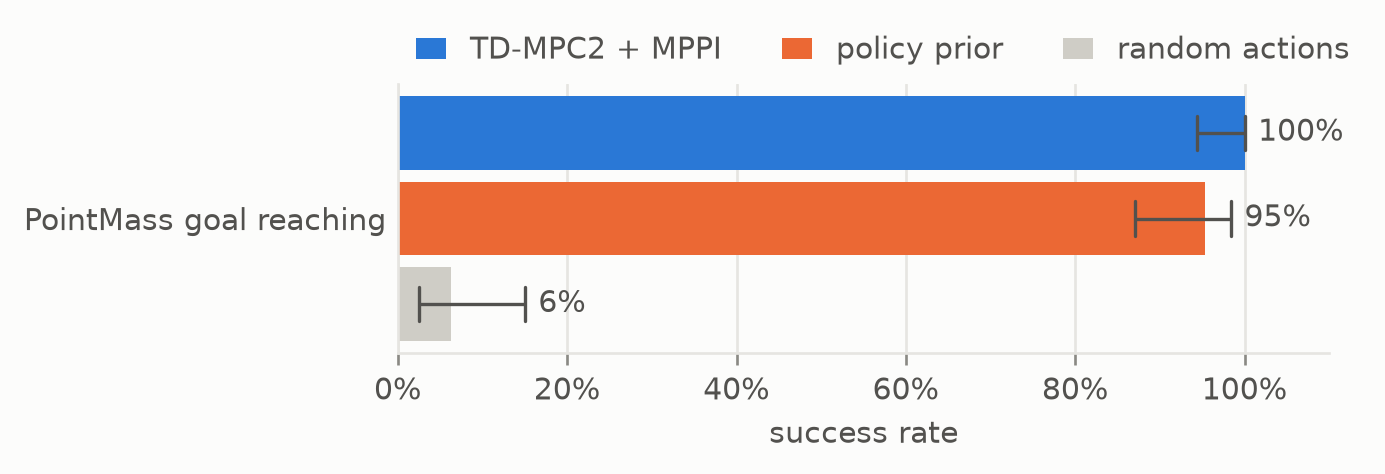

In [8]:
plots.bars({"PointMass goal reaching": result.intervals()}, xlabel="success rate", baseline="random actions")